# 도구 설치와 터미널

**이 노트북에서 할 일**

1. 임시 폴더 안에 `practice/data/message.txt` 파일을 만듭니다.
2. 기준 폴더 `practice`에서 상대 경로 `data/message.txt`로 파일을 읽습니다.
3. 기준 폴더를 한 칸 위로 잘못 잡아 실패를 보고, 기준 폴더만 고쳐 다시 읽습니다.

**준비물** — API 키 불필요. 데이터 파일도 없습니다. 노트북이 임시 폴더에 연습 파일을 직접 만듭니다.
모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

프로그램 설치는 교재 본문을 따라 직접 합니다. 이 노트북은 설치 명령을 실행하지 않습니다.

## 오늘 볼 그림

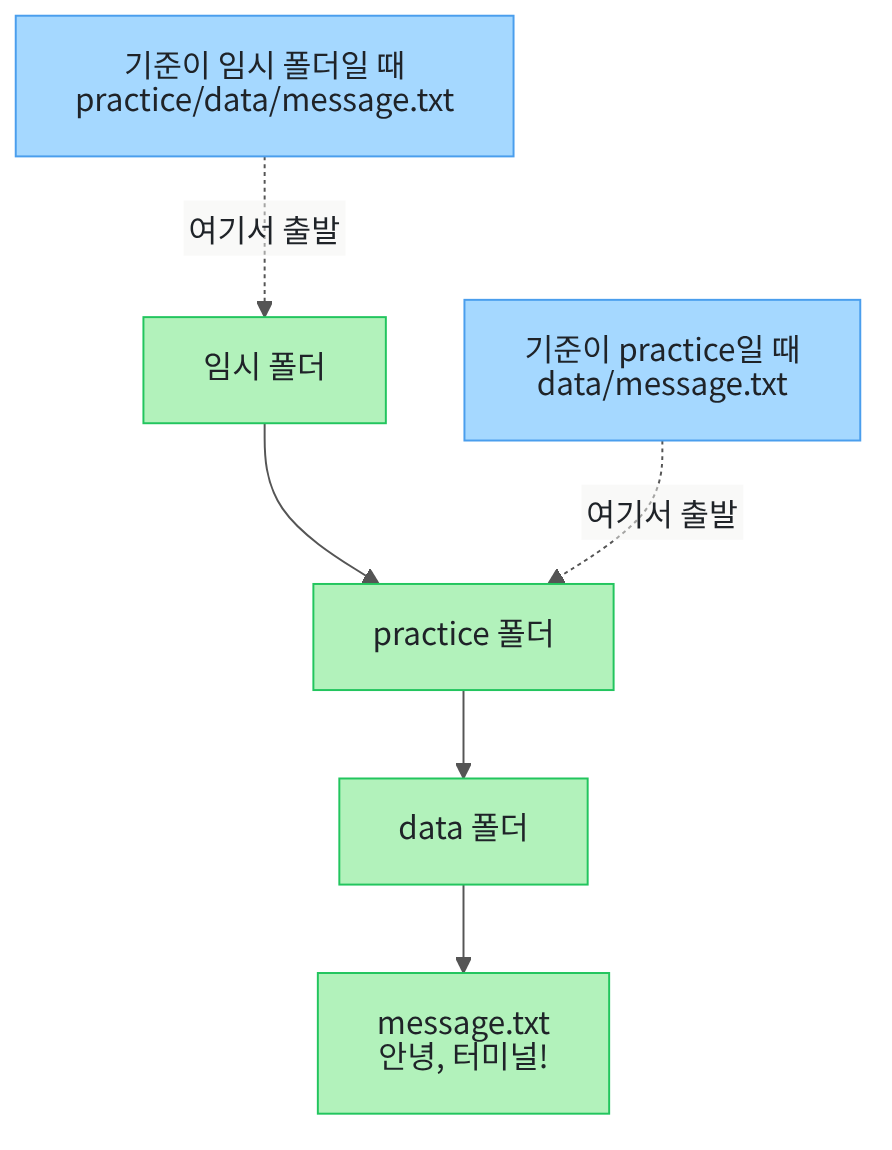

위에서 아래로 읽습니다. 초록 상자는 폴더와 파일이고, 파란 상자는 기준 폴더를 고른 두 경우입니다.
기준이 practice이면 `data/message.txt`로 파일에 닿습니다. 기준이 임시 폴더이면 `practice/data/message.txt`가 필요합니다.

## 1. 준비

이 절은 설치할 패키지가 없습니다. 이번에는 Python에 처음부터 들어 있는 기능 두 가지를 불러옵니다.
하나는 경로를 다루는 `Path`이고, 다른 하나는 임시 폴더를 만드는 `tempfile`입니다.
1절에서 본 불러오기 줄(`import`)로 이미 있는 기능을 이 노트북에서 쓸 수 있게 가져옵니다.

In [1]:
# 경로를 다루는 Path와 임시 폴더를 만드는 tempfile을 불러옵니다
import tempfile
from pathlib import Path

print("불러오기 완료")

불러오기 완료


**결과 읽기** — `불러오기 완료`가 보이면 다음 셀로 넘어갑니다.

## 2. 연습용 폴더 만들기

내 문서를 건드리지 않도록 임시 폴더에서 연습합니다. 임시 폴더는 연습이 끝나면 지워도 되는 빈 폴더입니다.

코드 `tempfile.TemporaryDirectory()`를 부르면 새 임시 폴더가 만들어집니다. 만든 폴더의 위치는 `.name`에 글자로 들어 있습니다.
이 글자를 `Path()`에 넣으면 경로를 다루는 값이 됩니다. 이 값을 `workspace`라는 이름에 저장합니다.

In [2]:
# 연습용 임시 폴더를 만들고 그 위치를 경로 값으로 바꿉니다
temporary_folder = tempfile.TemporaryDirectory()
# .name에는 임시 폴더의 위치가 글자로 들어 있습니다
workspace = Path(temporary_folder.name)
# is_dir()은 그 위치에 폴더가 있으면 True, 없으면 False를 반환합니다
print("임시 폴더가 있는가:", workspace.is_dir())

임시 폴더가 있는가: True


**결과 읽기** — `True`가 나왔습니다. 임시 폴더가 만들어졌다는 뜻입니다.
임시 폴더의 이름은 실행할 때마다 달라서 출력하지 않았습니다.

점 뒤에 이름과 괄호를 붙여 부르는 기능을 메서드(method)라고 합니다. 앞 셀의 `is_dir()`이 메서드입니다.

이번에는 임시 폴더 안에 `practice` 폴더를 만듭니다. 이 폴더가 연습 프로젝트 폴더 역할을 합니다.
경로 뒤의 슬래시 `/`는 나눗셈이 아닙니다. 폴더 경로 뒤에 이름을 한 칸 이어 붙입니다.

In [3]:
# 임시 폴더 안에 practice 폴더를 만듭니다
project = workspace / "practice"
print("만들기 전 practice 폴더가 있는가:", project.is_dir())
# mkdir()은 경로에 해당하는 폴더를 실제로 만듭니다
project.mkdir()
print("만든 뒤 practice 폴더가 있는가:", project.is_dir())

만들기 전 practice 폴더가 있는가: False
만든 뒤 practice 폴더가 있는가: True


**결과 읽기** — 만들기 전에는 `False`, 만든 뒤에는 `True`입니다.
경로를 이어 붙인 줄만으로는 폴더가 생기지 않았습니다. 메서드 `mkdir()`을 부른 뒤에 폴더가 생겼습니다.

폴더 `practice` 안에 `data` 폴더를 만들고, 그 안에 글 파일 `message.txt`를 저장합니다.
메서드 `write_text()`는 글을 파일에 저장합니다.
괄호 안에 넣어 메서드에 건네는 값을 인자라고 합니다. 인자 `encoding="utf-8"`은 한글을 저장하고 읽는 규칙입니다.

In [4]:
# practice 안에 data 폴더를 만들고 message.txt 파일에 글을 저장합니다
data_folder = project / "data"
data_folder.mkdir()
message_file = data_folder / "message.txt"
# write_text()는 글을 파일에 저장합니다. 읽을 때도 같은 utf-8 규칙을 씁니다
message_file.write_text("안녕, 터미널!", encoding="utf-8")
# is_file()은 그 위치에 파일이 있으면 True, 없으면 False를 반환합니다
print("message.txt 파일이 있는가:", message_file.is_file())

message.txt 파일이 있는가: True


**결과 읽기** — `True`입니다. 임시 폴더 안에 practice, data, message.txt가 차례로 들어 있습니다.

## 3. 두 기준 폴더에서 본 경로

상대 경로(relative path)는 기준 폴더에서 출발해 파일까지 가는 길입니다.
「두 번째 골목에서 왼쪽」이라는 설명이 서 있는 곳에 따라 다른 집을 가리키는 것과 같습니다.
메서드 `relative_to()`에 기준 폴더를 넣으면 그 폴더에서 파일까지의 경로를 반환합니다.
같은 파일을 practice와 임시 폴더, 두 곳을 기준으로 적어 봅니다.

In [5]:
# 같은 파일을 두 기준 폴더에서 본 상대 경로를 비교합니다
# relative_to(기준 폴더)는 기준 폴더에서 파일까지의 경로를 반환합니다
from_project = message_file.relative_to(project)
from_workspace = message_file.relative_to(workspace)
print("practice에서 본 경로:", from_project)
print("임시 폴더에서 본 경로:", from_workspace)

practice에서 본 경로: data/message.txt
임시 폴더에서 본 경로: practice/data/message.txt


**결과 읽기** — practice에서 보면 `data/message.txt`입니다. 한 칸 위인 임시 폴더에서 보면 `practice/data/message.txt`입니다.
파일은 하나인데 기준 폴더에 따라 적는 길이 다릅니다.
교재 출력은 슬래시(/)로 경로를 적는 환경에서 실행했습니다. Windows에서는 역슬래시로 보일 수 있습니다.

## 4. 기준 폴더에서 파일 읽기

이제 기준 폴더와 상대 경로를 이어 파일을 읽습니다.
터미널에서는 현재 작업 폴더가 기준 폴더입니다. 1절의 `price`처럼 값을 저장한 이름을 변수라고 합니다.
이 노트북에서는 변수 `base_folder`가 그 역할을 합니다.
메서드 `read_text()`는 파일 안의 글을 읽어 문자열로 반환합니다.

In [6]:
# 기준 폴더 practice에 상대 경로 data/message.txt를 이어 파일을 읽습니다
relative_path = Path("data/message.txt")
base_folder = project
basic_path = base_folder / relative_path
# read_text()는 파일 안의 글을 문자열로 반환합니다
basic_message = basic_path.read_text(encoding="utf-8")
print("기준 폴더:", base_folder.name)
print("상대 경로:", relative_path)
print("읽은 내용:", basic_message)

기준 폴더: practice
상대 경로: data/message.txt
읽은 내용: 안녕, 터미널!


**결과 읽기** — 기준 폴더 `practice`에서 `data/message.txt`를 따라가 `안녕, 터미널!`을 읽었습니다.
앞에서 저장한 글과 같습니다.

## Before: 기준 폴더를 한 칸 위로 잡은 경우

터미널을 practice가 아니라 그 위 폴더에서 연 상황입니다. 상대 경로는 그대로 `data/message.txt`를 씁니다.
실행 전에 예상합니다. 임시 폴더 바로 아래에는 data 폴더가 없으므로 파일도 찾지 못할 것입니다.
두 경로 값이 같은 위치인지는 등호 두 개 `==`로 비교합니다.

In [7]:
# Before: 기준 폴더를 한 칸 위인 임시 폴더로 잘못 잡습니다
wrong_base = workspace
wrong_path = wrong_base / relative_path
print("기준 폴더가 practice인가:", wrong_base == project)
print("그 위치에 파일이 있는가:", wrong_path.is_file())

기준 폴더가 practice인가: False
그 위치에 파일이 있는가: False


**결과 읽기** — 두 줄 모두 `False`입니다. 기준 폴더가 practice가 아닙니다.
그래서 이어 붙인 위치에 파일이 없습니다. 파일은 지워지지 않았고, 요청한 위치에서 찾지 못했을 뿐입니다.

### 원리 더 알아보기 — 실제로 읽으면 나오는 오류

파일이 없는 위치를 읽으면 오류가 나고 셀 실행이 멈춥니다.
아래 셀은 멈추지 않고 오류 이름만 보려고 `try`와 `except`를 씁니다. 이 문법은 Ch 2에서 배우므로 지금은 출력만 읽습니다.

In [8]:
# 원리 더 알아보기: 잘못된 위치의 파일을 실제로 읽어 오류 이름을 확인합니다
try:
    wrong_path.read_text(encoding="utf-8")
    print("오류 없이 읽었습니다")
except FileNotFoundError as error:
    print("오류 이름:", type(error).__name__)
    print("찾지 못한 파일 이름:", Path(error.filename).name)

오류 이름: FileNotFoundError
찾지 못한 파일 이름: message.txt


**결과 읽기** — 오류 이름은 `FileNotFoundError`이고, 찾지 못한 파일은 `message.txt`입니다.
이 오류는 요청한 위치에 그 파일이 없다는 뜻입니다. 컴퓨터 어디에도 없다는 뜻은 아닙니다.

## After: 기준 폴더만 practice로 고치기

상대 경로는 그대로 두고 기준 폴더만 practice로 고칩니다. 파일은 새로 만들지 않습니다.
실행 전에 예상합니다. 이번에는 두 줄 모두 `True`가 나올 것입니다.

In [9]:
# After: 기준 폴더만 practice로 고치고 같은 상대 경로를 씁니다
right_base = project
right_path = right_base / relative_path
print("기준 폴더가 practice인가:", right_base == project)
print("그 위치에 파일이 있는가:", right_path.is_file())

기준 폴더가 practice인가: True
그 위치에 파일이 있는가: True


**결과 읽기** — 두 줄 모두 `True`입니다. 앞의 Before와 달라진 것은 기준 폴더 하나뿐입니다.

파일이 있다는 것만으로는 원하는 파일인지 알 수 없습니다. 같은 이름의 다른 파일일 수도 있습니다.
다음 셀에서 내용을 읽고 처음 저장한 글과 비교합니다.

In [10]:
# 고친 경로로 파일을 읽고 처음 저장한 글과 같은지 비교합니다
right_message = right_path.read_text(encoding="utf-8")
same = right_message == "안녕, 터미널!"
print("읽은 내용:", right_message)
print("저장한 글과 같은가:", same)
# 같지 않으면 이 줄에서 실행을 멈춥니다
assert same

읽은 내용: 안녕, 터미널!
저장한 글과 같은가: True


**결과 읽기** — 읽은 내용은 `안녕, 터미널!`이고 비교 결과는 `True`입니다. 검사 줄 `assert`에서 멈추지 않았습니다.

## 값 바꿔 보기: 기준은 그대로, 상대 경로를 길게

이번에는 다른 쪽을 고쳐 봅니다. 기준 폴더는 임시 폴더 그대로 두고, 상대 경로 앞에 practice를 붙입니다.
실행 전에 예상합니다. 임시 폴더에서 본 경로는 `practice/data/message.txt`였으므로 파일을 찾을 것입니다.
마지막 줄은 이 경로가 After의 경로와 같은 위치인지 비교합니다.

In [11]:
# 기준은 임시 폴더 그대로 두고, 상대 경로를 practice부터 적습니다
longer_path = Path("practice/data/message.txt")
workspace_path = workspace / longer_path
print("상대 경로:", longer_path)
print("그 위치에 파일이 있는가:", workspace_path.is_file())
print("After 경로와 같은 위치인가:", workspace_path == right_path)

상대 경로: practice/data/message.txt
그 위치에 파일이 있는가: True
After 경로와 같은 위치인가: True


**결과 읽기** — 파일 확인 결과가 `True`입니다. After 경로와 같은 위치인지도 `True`입니다.
기준 폴더와 상대 경로를 이으면 실제 위치가 정해집니다. 이번에는 두 방법 모두 같은 파일에 닿았습니다.

## 5. 임시 폴더 정리하기

연습이 끝났으므로 임시 폴더를 지웁니다. 메서드 `cleanup()`은 임시 폴더와 그 안의 파일을 함께 지웁니다.
이 노트북이 만든 임시 폴더만 지우고, 다른 폴더는 건드리지 않습니다.

In [12]:
# 연습용 임시 폴더를 지우고 남아 있는지 확인합니다
temporary_folder.cleanup()
print("임시 폴더가 남아 있는가:", workspace.is_dir())

임시 폴더가 남아 있는가: False


**결과 읽기** — `False`입니다. 임시 폴더와 안의 파일이 지워졌습니다.

## 정리

- 상대 경로는 기준 폴더에서 출발합니다. 같은 `data/message.txt`도 기준 폴더에 따라 찾는 곳이 달라집니다.
- 기준 폴더가 한 칸 위일 때는 파일을 찾지 못했습니다. 기준 폴더만 고치자 저장한 글을 그대로 읽었습니다.
- 파일이 있는지 확인한 뒤 내용도 읽어 원하는 파일인지 확인합니다.

프로그램 설치와 터미널 명령 입력은 이 노트북에서 실행하지 않았습니다.
다음 절에서는 교재가 준비한 실습 폴더에 Python 3.12 실행 환경을 준비합니다.